# UNSB 가상 염색 노트북 (메인 기법)

커널 **Python (blood)**, 위에서부터 `Shift + Enter`. 실험 계획 문서의 **2번 실험**입니다.

**UNSB** (Unpaired Neural Schrödinger Bridge, Kim et al., ICLR 2024): 비염색 → 염색을 한 번에 바꾸지 않고 **여러 단계(기본 5단계)에 걸쳐 조금씩** 바꾸는 diffusion 계열 방법. 단계마다 "같은 위치 조각은 같은 내용"이 되도록 하는 대조 손실(CUT의 PatchNCE)이 걸려 있어 **세포 구조를 지키도록** 설계됨. 짝 데이터 필요 없음.

| 단계 | 하는 일 | 시간 |
| --- | --- | --- |
| 0 | 폴더 이동 | 바로 |
| 1 | UNSB 공식 코드 받기 (한 번만) | 1분 |
| 2 | 학습 (짧은 테스트 → 본 학습) | 본 학습 수 시간~반나절 |
| 3 | epoch 고르기 (val 9장) | 수십 분 |
| 4 | 최종 채점 (test 91장, 한 번만) | 수십 분 |
| 5 | 눈으로 확인 + 비교표 | 바로 |

**데이터·규칙은 CycleGAN과 같음**: 학습 `3_virtual_staining/rbc_only` (A 비염색 RedTell · B 염색 TXL), val 9장으로 epoch 고르기(RBC F1 최고), test 91장 한 번 채점, YOLO conf 0.7.

**저장 위치**: 가중치 `runs/unsb/unsb_rbc/` · 가상 염색 `06. Generate/unsb/ep<숫자>/{val,test}/` · 채점 `07. Evaluate/3_staining/unsb/ep<숫자>_{val,test}/`

## 0. 폴더 이동 (노트북을 열 때마다 먼저)

In [1]:
import torch, os, sys
print('GPU:', torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')
os.chdir(r'D:\05. Blood\05. Train\code')
print('스크립트 실행 파이썬:', sys.executable)
UREPO = r"D:/05. Blood/05. Train/external/unsb"

GPU: True NVIDIA GeForce RTX 5060 Ti
스크립트 실행 파이썬: C:\Users\KonYang\anaconda3\envs\blood\python.exe


## 1. UNSB 공식 코드 받기 (처음 한 번만)
저자 공식 저장소(cyclomon/UNSB)를 `05. Train/external/unsb`에 받고, 테스트한 버전(2024-04, `d1f644f`)으로 고정합니다. CycleGAN 때 설치한 `dominate` 외에 `packaging`이 필요합니다.

In [2]:
%pip install packaging dominate
!git clone https://github.com/cyclomon/UNSB.git "D:/05. Blood/05. Train/external/unsb"
!git -C "D:/05. Blood/05. Train/external/unsb" checkout d1f644f

Note: you may need to restart the kernel to use updated packages.


Cloning into 'D:/05. Blood/05. Train/external/unsb'...
Note: switching to 'd1f644f'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at d1f644f Update README.md


## 2. UNSB 학습

설정: 공식 horse2zebra 설정(`--lambda_SB 1.0 --lambda_NCE 1.0`, 기본 mode sb, 5단계, tau 0.01) 그대로 + 아래만 바꿈
- `--preprocess none --load_size 128 --crop_size 128`: 우리 조각 크기 (공식은 256)
- `--n_epochs 25 --n_epochs_decay 25`: **50 epoch** (CycleGAN과 같게. 공식 기본은 400이라 시간상 줄임), `--save_epoch_freq 5`
- `--display_id 0`: 공식 코드가 기본으로 쓰는 visdom 서버 끄기
- `--num_threads 0`: 윈도우 데이터 로더 에러 방지
- 흑백 비염색은 3채널로 넣음 (UNSB는 한 방향만 학습해서 CycleGAN 1차 때의 역방향 문제가 없음)

### 2-1. 짧은 테스트 (2~3분). `End of epoch 1 / 1`이 나오면 성공. 출력의 `time:` = 1장 처리 시간(초)

In [3]:
!{sys.executable} "D:/05. Blood/05. Train/external/unsb/train.py" --dataroot "D:/05. Blood/04. Prep/3_virtual_staining/rbc_only" --name unsb_smoke --lambda_SB 1.0 --lambda_NCE 1.0 --gpu_ids 0 --checkpoints_dir "D:/05. Blood/05. Train/runs/unsb" --preprocess none --load_size 128 --crop_size 128 --n_epochs 1 --n_epochs_decay 0 --max_dataset_size 200 --num_threads 0 --display_id 0 --print_freq 50 --display_freq 100000

----------------- Options ---------------
               batch_size: 1                             
                    beta1: 0.5                           
                    beta2: 0.999                         
          checkpoints_dir: D:/05. Blood/05. Train/runs/unsb	[default: ./checkpoints]
           continue_train: False                         
                crop_size: 128                           	[default: 256]
                 dataroot: D:/05. Blood/04. Prep/3_virtual_staining/rbc_only	[default: placeholder]
             dataset_mode: unaligned                     
                direction: AtoB                          
              display_env: main                          
             display_freq: 100000                        	[default: 400]
               display_id: 0                             	[default: None]
            display_ncols: 4                             
             display_port: 8097                          
           display_server: http

D:\05. Blood\05. Train\external\unsb\models\networks.py:578: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  patch_id = torch.tensor(patch_id, dtype=torch.long, device=feat.device)
D:\05. Blood\05. Train\external\unsb\models\base_model.py:161: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  errors_ret[name] = float(getattr(self, 'loss_' + name))  # float(...) works for both scalar tensor and float number


### 2-2. 본 학습
- 1 epoch ≈ 4,800 iteration (비염색 조각 수). 예상 시간 ≈ 2-1의 `time` × 4,800 × 50 초
  - 예: `time: 0.2` → 약 13시간. 너무 길면 아래 명령에서 `--n_epochs 15 --n_epochs_decay 15` (30 epoch)로 줄이기
- 노트북 창을 닫지 마세요. 끊기면 같은 명령 끝에 `--continue_train --epoch_count <다음 epoch>`
- 중간 결과 그림: `runs/unsb/unsb_rbc/web/index.html`

In [4]:
!{sys.executable} "D:/05. Blood/05. Train/external/unsb/train.py" --dataroot "D:/05. Blood/04. Prep/3_virtual_staining/rbc_only" --name unsb_rbc --lambda_SB 1.0 --lambda_NCE 1.0 --gpu_ids 0 --checkpoints_dir "D:/05. Blood/05. Train/runs/unsb" --preprocess none --load_size 128 --crop_size 128 --n_epochs 25 --n_epochs_decay 25 --save_epoch_freq 5 --num_threads 0 --display_id 0 --print_freq 1000 --display_freq 5000 --update_html_freq 5000

----------------- Options ---------------
               batch_size: 1                             
                    beta1: 0.5                           
                    beta2: 0.999                         
          checkpoints_dir: D:/05. Blood/05. Train/runs/unsb	[default: ./checkpoints]
           continue_train: False                         
                crop_size: 128                           	[default: 256]
                 dataroot: D:/05. Blood/04. Prep/3_virtual_staining/rbc_only	[default: placeholder]
             dataset_mode: unaligned                     
                direction: AtoB                          
              display_env: main                          
             display_freq: 5000                          	[default: 400]
               display_id: 0                             	[default: None]
            display_ncols: 4                             
             display_port: 8097                          
           display_server: http

D:\05. Blood\05. Train\external\unsb\models\networks.py:578: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  patch_id = torch.tensor(patch_id, dtype=torch.long, device=feat.device)
D:\05. Blood\05. Train\external\unsb\models\base_model.py:161: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  errors_ret[name] = float(getattr(self, 'loss_' + name))  # float(...) works for both scalar tensor and float number


## 3. epoch 고르기 (val 9장으로만)
**규칙: val RBC F1이 가장 높은 epoch.** 변환은 128 조각 단위로 5단계 샘플링 후 겹쳐 붙임 (`23_apply_unsb.py`, seed 0 고정).
UNSB는 단계마다 생성기를 다시 돌려서 CycleGAN보다 변환이 느립니다 (장당 수 초).

In [5]:
EPOCHS = list(range(5, 51, 5))   # 2-2를 30 epoch로 줄였으면 range(5, 31, 5)
for e in EPOCHS:
    !{sys.executable} 23_apply_unsb.py --repo "D:/05. Blood/05. Train/external/unsb" --ckpt "D:/05. Blood/05. Train/runs/unsb/unsb_rbc" --epoch {e} --images "D:/05. Blood/04. Prep/4_eval_unstained/redtell_dse_val/images" --out "D:/05. Blood/06. Generate/unsb/ep{e}/val"
    !{sys.executable} 12_eval_compare.py --prep "D:/05. Blood/04. Prep" --images "D:/05. Blood/06. Generate/unsb/ep{e}/val" --labels "D:/05. Blood/04. Prep/4_eval_unstained/redtell_dse_val/labels" --yolo "D:/05. Blood/05. Train/runs/yolo/yolo11s/weights/best.pt" --conf 0.7 --out "D:/05. Blood/07. Evaluate/3_staining/unsb/ep{e}_val"

UNSB 가상 염색 9장 완료 (epoch 5, NFE 5, 조각 128, 장당 6101 ms) → D:/05. Blood/05. Train/virtual_stained/unsb/ep5/val

[YOLO]
  method: YOLO
  n_images: 9
  WBC_MAE: 0.0
  WBC_precision: 0.0
  WBC_recall: 0.0
  WBC_F1: 0.0
  RBC_MAE: 7.889
  RBC_precision: 0.7309
  RBC_recall: 0.8757
  RBC_F1: 0.7968
  WBC_rel_error: 
  RBC_rel_error: 0.2947
  ms_per_image: 15.1

����옣: D:/05. Blood/05. Train/results/3_staining/unsb/ep5_val
UNSB 가상 염색 9장 완료 (epoch 10, NFE 5, 조각 128, 장당 5920 ms) → D:/05. Blood/05. Train/virtual_stained/unsb/ep10/val

[YOLO]
  method: YOLO
  n_images: 9
  WBC_MAE: 0.0
  WBC_precision: 0.0
  WBC_recall: 0.0
  WBC_F1: 0.0
  RBC_MAE: 15.222
  RBC_precision: 0.6568
  RBC_recall: 0.9231
  RBC_F1: 0.7675
  WBC_rel_error: 
  RBC_rel_error: 0.5331
  ms_per_image: 9.9

����옣: D:/05. Blood/05. Train/results/3_staining/unsb/ep10_val
UNSB 가상 염색 9장 완료 (epoch 15, NFE 5, 조각 128, 장당 5940 ms) → D:/05. Blood/05. Train/virtual_stained/unsb/ep15/val

[YOLO]
  method: YOLO
  n_images: 9
  WBC_MAE: 0.0

In [6]:
import pandas as pd
cols = ["epoch", "RBC_MAE", "RBC_precision", "RBC_recall", "RBC_F1"]
rows = [pd.read_csv(rf"D:/05. Blood/07. Evaluate/2_no_staining/stain_none_val/summary.csv").assign(epoch="가상 염색 없음")]
rows += [pd.read_csv(rf"D:/05. Blood/07. Evaluate/3_staining/unsb/ep{e}_val/summary.csv").assign(epoch=e) for e in EPOCHS]
tab = pd.concat(rows)[cols]
display(tab)
best = tab[tab.epoch != "가상 염색 없음"].sort_values("RBC_F1", ascending=False).iloc[0]
print("val RBC F1 최고 epoch:", best.epoch)

,epoch,RBC_MAE,RBC_precision,RBC_recall,RBC_F1
0,가상 염색 없음,10.111,0.9757,0.7130,0.8239
0,5,7.889,0.7309,0.8757,0.7968
0,10,15.222,0.6568,0.9231,0.7675
0,15,8.333,0.7482,0.9142,0.8229
0,20,9.000,0.7064,0.8757,0.7820
0,25,9.000,0.7410,0.9142,0.8185
0,30,12.444,0.6800,0.9053,0.7766
0,35,11.444,0.6871,0.8964,0.7779
0,40,12.111,0.6957,0.9201,0.7924
0,45,12.556,0.6851,0.9142,0.7833


val RBC F1 최고 epoch: 15


## 4. 최종 채점 (test 91장) — `BEST_EPOCH`를 3번 결과로 바꾸고 **한 번만**

In [7]:
BEST_EPOCH = 50   # ← 3번 결과로 바꾸기
!{sys.executable} 23_apply_unsb.py --repo "D:/05. Blood/05. Train/external/unsb" --ckpt "D:/05. Blood/05. Train/runs/unsb/unsb_rbc" --epoch {BEST_EPOCH} --images "D:/05. Blood/04. Prep/4_eval_unstained/redtell_dse/images" --out "D:/05. Blood/06. Generate/unsb/ep{BEST_EPOCH}/test"
!{sys.executable} 12_eval_compare.py --prep "D:/05. Blood/04. Prep" --images "D:/05. Blood/06. Generate/unsb/ep{BEST_EPOCH}/test" --labels "D:/05. Blood/04. Prep/4_eval_unstained/redtell_dse/labels" --yolo "D:/05. Blood/05. Train/runs/yolo/yolo11s/weights/best.pt" --conf 0.7 --out "D:/05. Blood/07. Evaluate/3_staining/unsb/ep{BEST_EPOCH}_test"

UNSB 가상 염색 91장 완료 (epoch 50, NFE 5, 조각 128, 장당 5554 ms) → D:/05. Blood/05. Train/virtual_stained/unsb/ep50/test

[YOLO]
  method: YOLO
  n_images: 91
  WBC_MAE: 0.0
  WBC_precision: 0.0
  WBC_recall: 0.0
  WBC_F1: 0.0
  RBC_MAE: 10.714
  RBC_precision: 0.6996
  RBC_recall: 0.8938
  RBC_F1: 0.7848
  WBC_rel_error: 
  RBC_rel_error: 0.3756
  ms_per_image: 11.8

����옣: D:/05. Blood/05. Train/results/3_staining/unsb/ep50_test


## 5. 눈으로 확인 + 비교표
초록 선 = 실제 세포 위치(정답 윤곽). 가짜 세포가 생기거나 세포가 사라졌는지 봅니다.

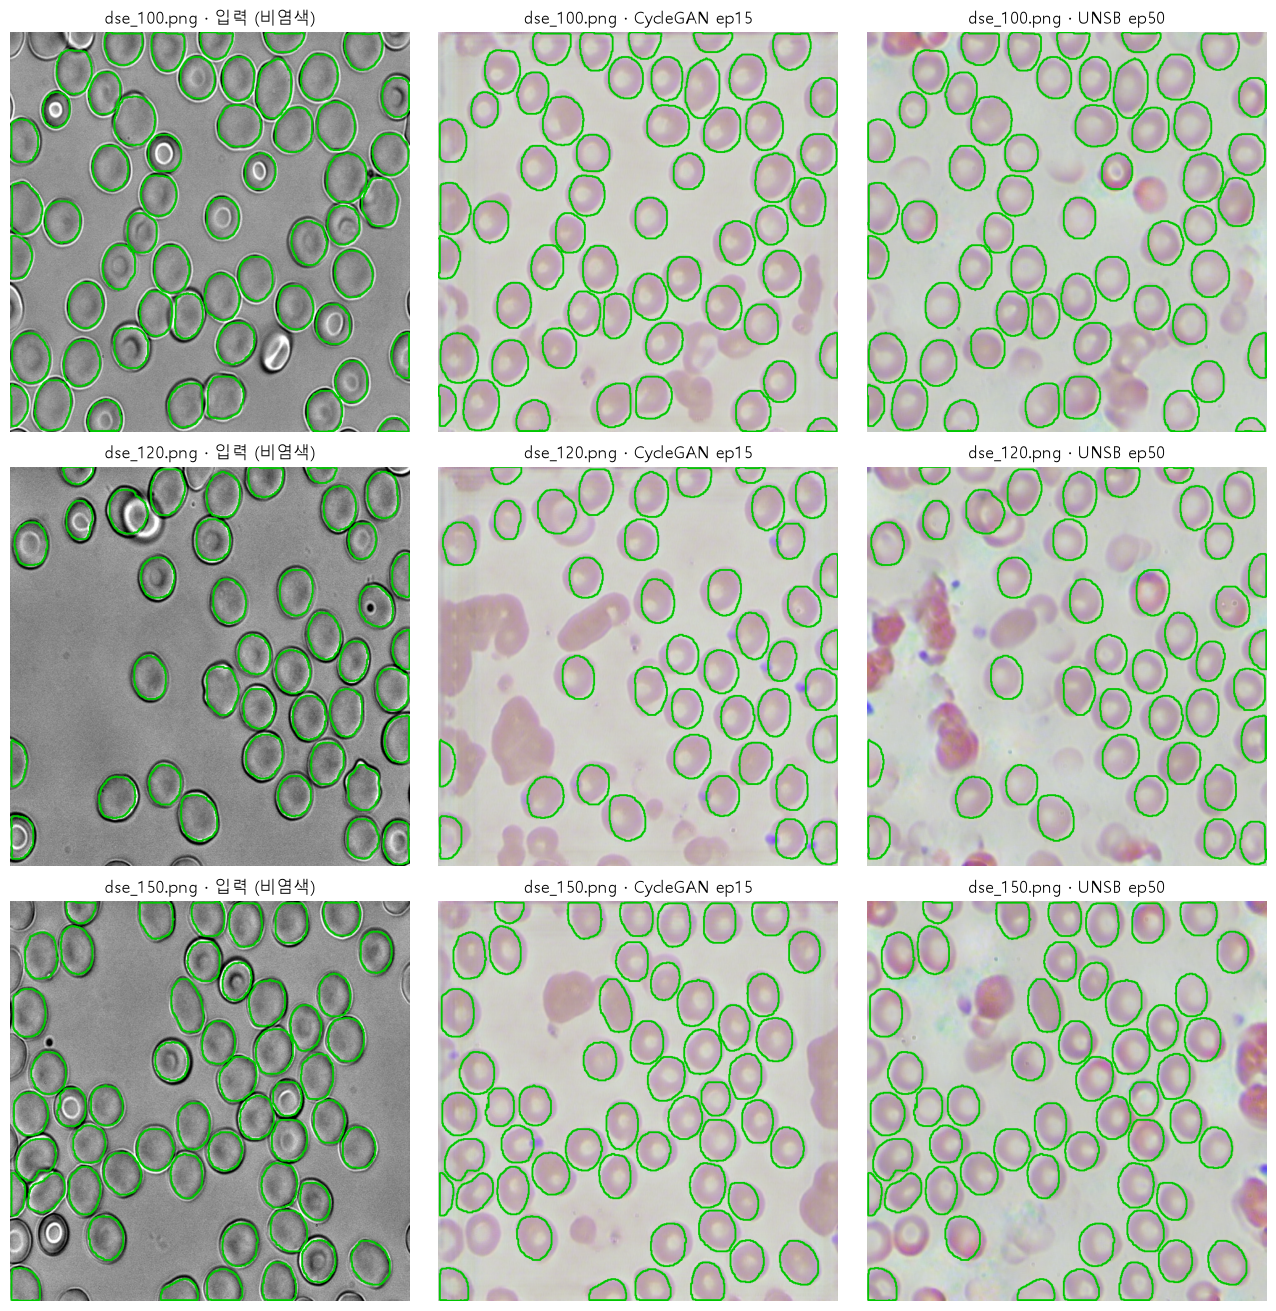

In [8]:
import matplotlib.pyplot as plt, numpy as np, cv2
plt.rcParams["font.family"] = "Malgun Gothic"; plt.rcParams["axes.unicode_minus"] = False
rd = lambda p, f=1: cv2.imdecode(np.fromfile(p, np.uint8), f)
CG = 15
names = ["dse_100.png", "dse_120.png", "dse_150.png"]
fig, ax = plt.subplots(len(names), 3, figsize=(13, 4.4 * len(names)))
for i, n in enumerate(names):
    gt = rd(rf"D:/05. Blood/04. Prep/4_eval_unstained/redtell_dse/masks/{n}", -1)
    edge = np.zeros(gt.shape, np.uint8)
    for v in np.unique(gt)[1:]:
        c, _ = cv2.findContours((gt == v).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE); cv2.drawContours(edge, c, -1, 255, 2)
    ims = [cv2.cvtColor(rd(rf"D:/05. Blood/04. Prep/4_eval_unstained/redtell_dse/images/{n}", 0), cv2.COLOR_GRAY2RGB),
           cv2.cvtColor(rd(rf"D:/05. Blood/06. Generate/cyclegan/ep{CG}/test/{n}"), cv2.COLOR_BGR2RGB),
           cv2.cvtColor(rd(rf"D:/05. Blood/06. Generate/unsb/ep{BEST_EPOCH}/test/{n}"), cv2.COLOR_BGR2RGB)]
    for j, (im, t) in enumerate(zip(ims, ["입력 (비염색)", f"CycleGAN ep{CG}", f"UNSB ep{BEST_EPOCH}"])):
        im = im.copy(); im[edge > 0] = (0, 200, 0)
        ax[i, j].imshow(im); ax[i, j].set_title(f"{n} · {t}"); ax[i, j].axis("off")
plt.tight_layout(); plt.show()

In [9]:
import pandas as pd
cols = ["model", "RBC_MAE", "RBC_precision", "RBC_recall", "RBC_F1"]
t = pd.concat([pd.read_csv(rf"D:/05. Blood/07. Evaluate/2_no_staining/stain_none_test/summary.csv").assign(model="비염색 그대로 (하한)"),
               pd.read_csv(rf"D:/05. Blood/07. Evaluate/3_staining/cyclegan/ep15_test/summary.csv").assign(model="CycleGAN 1차 ep15"),
               pd.read_csv(rf"D:/05. Blood/07. Evaluate/3_staining/unsb/ep{BEST_EPOCH}_test/summary.csv").assign(model=f"UNSB ep{BEST_EPOCH}")])
display(t[cols])

,model,RBC_MAE,RBC_precision,RBC_recall,RBC_F1
0,비염색 그대로 (하한),9.846,0.9736,0.7252,0.8313
0,CycleGAN 1차 ep15,7.769,0.7073,0.8388,0.7675
0,UNSB ep50,10.714,0.6996,0.8938,0.7848
